In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, 
                                   LabelEncoder, OneHotEncoder)



In [2]:
titanic_df = sns.load_dataset('titanic')
titanic_df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [41]:
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
 15  Sex          891 non-null    object  
dtypes: bool(2), category(2), float64(2), int64(4), object(6)
memory usage: 87.6+ KB


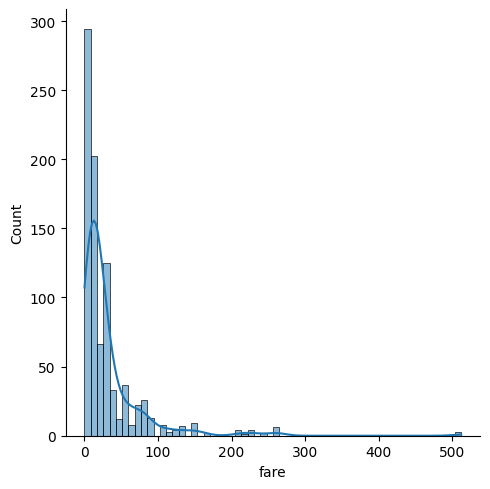

In [18]:
titanic_df['fare']
sns.displot(titanic_df['fare'],kde=True)

c:\Users\v-maheshkur\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


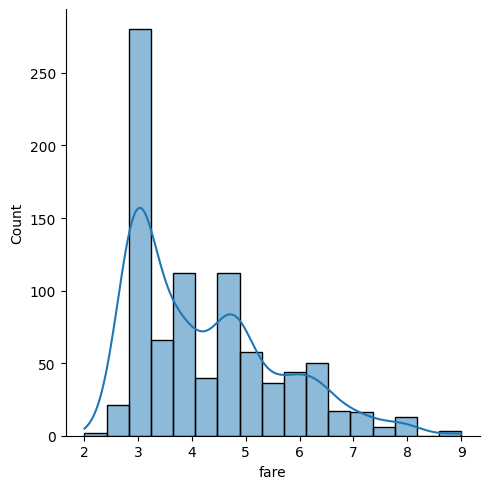

In [17]:
sns.displot(np.log2(titanic_df['fare']),kde=True)

In [ ]:
np.log2(titanic_df['fare'])

c:\Users\v-maheshkur\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


0      2.857981
1      6.155492
2      2.986411
3      5.730640
4      3.008989
         ...   
886    3.700440
887    4.906891
888    4.551516
889    4.906891
890    2.954196
Name: fare, Length: 891, dtype: float64

In [19]:
gender_df = pd.DataFrame({'Sex': np.random.choice(['male', 'female', 'M','F'], 891)})

In [24]:
titanic_df = pd.concat([titanic_df, gender_df], axis=1)

In [30]:
titanic_df['Sex']

0      female
1           F
2           M
3      female
4           F
        ...  
886    female
887         F
888         F
889      male
890      male
Name: Sex, Length: 891, dtype: object

In [39]:
def convert_gender(X):
    if X == 'F':
        return "female"
    elif X == 'M':
        return "male"
    else:
        return X

titanic_df['Sex'] = titanic_df['Sex'].map(convert_gender)

In [28]:
titanic_df['Sex'].replace({'F': 'female', 'M':'male'})

0      female
1      female
2        male
3      female
4      female
        ...  
886    female
887    female
888    female
889      male
890      male
Name: Sex, Length: 891, dtype: object

In [42]:
titanic_df.select_dtypes(include=['O', 'category'])

,sex,embarked,class,who,deck,embark_town,alive,Sex
0,male,S,Third,man,NaN,Southampton,no,female
1,female,C,First,woman,C,Cherbourg,yes,female
2,female,S,Third,woman,NaN,Southampton,yes,male
3,female,S,First,woman,C,Southampton,yes,female
4,male,S,Third,man,NaN,Southampton,no,female
...,...,...,...,...,...,...,...,...
886,male,S,Second,man,NaN,Southampton,no,female
887,female,S,First,woman,B,Southampton,yes,female
888,female,S,Third,woman,NaN,Southampton,no,female
889,male,C,First,man,C,Cherbourg,yes,male


In [ ]:
titanic_df['Sex'].replace({'F': 'female', 'M':'male'})

In [45]:
titanic_df['alive'].value_counts()

alive
no     549
yes    342
Name: count, dtype: int64

In [46]:
titanic_df['alive'].replace({'no': '0', 'yes':'1'})

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: alive, Length: 891, dtype: object

In [48]:
from sklearn.preprocessing import LabelBinarizer

bin = LabelBinarizer()
bin.fit_transform(titanic_df[['alive']])

array([[0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [1],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
    

In [53]:
titanic_df[['embark_town']].head(6)

,embark_town
0,Southampton
1,Cherbourg
2,Southampton
3,Southampton
4,Southampton
5,Queenstown


In [64]:
pd.get_dummies(titanic_df['embark_town'], dtype=int, drop_first=True)

,Queenstown,Southampton
0,0,1
1,0,0
2,0,1
3,0,1
4,0,1
...,...,...
886,0,1
887,0,1
888,0,1
889,0,0


In [ ]:
from sklearn.preprocessing import OneHotEncoder

oh_enc = OneHotEncoder(sparse_output=False,  drop=[np.nan])
oh_enc.fit_transform( titanic_df[['embark_town']])
# oh_enc.categories_


array([[0., 0., 1.],
       [1., 0., 0.],
       [0., 0., 1.],
       ...,
       [0., 0., 1.],
       [1., 0., 0.],
       [0., 1., 0.]], shape=(891, 3))

In [81]:
oh_enc.categories_
# oh_enc.feature_names_in_

[array(['Cherbourg', 'Queenstown', 'Southampton', nan], dtype=object)]

In [72]:
titanic_df[['embark_town']].value_counts()

embark_town
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [60]:
titanic_df[['embark_town', 'embark_town_encoded']].head(10)

,embark_town,embark_town_encoded
0,Southampton,2.0
1,Cherbourg,0.0
2,Southampton,2.0
3,Southampton,2.0
4,Southampton,2.0
5,Queenstown,1.0
6,Southampton,2.0
7,Southampton,2.0
8,Southampton,2.0
9,Cherbourg,0.0


In [86]:
titanic_df['class'].unique()

['Third', 'First', 'Second']
Categories (3, object): ['First', 'Second', 'Third']

In [97]:
from sklearn.preprocessing import OrdinalEncoder


ord_enc = OrdinalEncoder()
ord_enc.fit_transform(titanic_df[['class']])

array([[2.],
       [0.],
       [2.],
       [0.],
       [2.],
       [2.],
       [0.],
       [2.],
       [2.],
       [1.],
       [2.],
       [0.],
       [2.],
       [2.],
       [2.],
       [1.],
       [2.],
       [1.],
       [2.],
       [2.],
       [1.],
       [1.],
       [2.],
       [0.],
       [2.],
       [2.],
       [2.],
       [0.],
       [2.],
       [2.],
       [0.],
       [0.],
       [2.],
       [1.],
       [0.],
       [0.],
       [2.],
       [2.],
       [2.],
       [2.],
       [2.],
       [1.],
       [2.],
       [1.],
       [2.],
       [2.],
       [2.],
       [2.],
       [2.],
       [2.],
       [2.],
       [2.],
       [0.],
       [1.],
       [0.],
       [0.],
       [1.],
       [2.],
       [1.],
       [2.],
       [2.],
       [0.],
       [0.],
       [2.],
       [0.],
       [2.],
       [1.],
       [2.],
       [2.],
       [2.],
       [1.],
       [2.],
       [1.],
       [2.],
       [2.],
       [2.],
       [2.],

In [96]:
from sklearn.preprocessing import OrdinalEncoder


ord_enc = OrdinalEncoder(categories=[['Second', 'First', 'Third']])
ord_enc.fit_transform(titanic_df[['class']])

array([[2.],
       [1.],
       [2.],
       [1.],
       [2.],
       [2.],
       [1.],
       [2.],
       [2.],
       [0.],
       [2.],
       [1.],
       [2.],
       [2.],
       [2.],
       [0.],
       [2.],
       [0.],
       [2.],
       [2.],
       [0.],
       [0.],
       [2.],
       [1.],
       [2.],
       [2.],
       [2.],
       [1.],
       [2.],
       [2.],
       [1.],
       [1.],
       [2.],
       [0.],
       [1.],
       [1.],
       [2.],
       [2.],
       [2.],
       [2.],
       [2.],
       [0.],
       [2.],
       [0.],
       [2.],
       [2.],
       [2.],
       [2.],
       [2.],
       [2.],
       [2.],
       [2.],
       [1.],
       [0.],
       [1.],
       [1.],
       [0.],
       [2.],
       [0.],
       [2.],
       [2.],
       [1.],
       [1.],
       [2.],
       [1.],
       [2.],
       [0.],
       [2.],
       [2.],
       [2.],
       [0.],
       [2.],
       [0.],
       [2.],
       [2.],
       [2.],
       [2.],

{'categories': 'auto',
 'dtype': numpy.float64,
 'encoded_missing_value': nan,
 'handle_unknown': 'error',
 'max_categories': None,
 'min_frequency': None,
 'unknown_value': None}

In [5]:
titanic_df['fare'].quantile(0.50)

np.float64(14.4542)

In [7]:
Q1 = titanic_df['fare'].quantile(0.25)
Q3 = titanic_df['fare'].quantile(0.75)
IQR = Q3 - Q1

IQR

np.float64(23.0896)

In [8]:
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

lower_fence, upper_fence

(np.float64(-26.724), np.float64(65.6344))

In [15]:
titanic_df[(titanic_df['fare'] < upper_fence) & (titanic_df['fare'] > lower_fence) ]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [17]:
from scipy import stats


titanic_df['z-score_fare'] = stats.zscore(titanic_df['fare'])

In [21]:
titanic_df[(titanic_df['z-score_fare'] > 3) | (titanic_df['z-score_fare'] < -3)]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,z-score_fare
27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False,4.647001
88,1,1,female,23.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False,4.647001
118,0,1,male,24.0,0,1,247.5208,C,First,man,True,B,Cherbourg,no,False,4.335332
258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True,9.667167
299,1,1,female,50.0,0,1,247.5208,C,First,woman,False,B,Cherbourg,yes,False,4.335332
311,1,1,female,18.0,2,2,262.3750,C,First,woman,False,B,Cherbourg,yes,False,4.634417
341,1,1,female,24.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False,4.647001
377,0,1,male,27.0,0,2,211.5000,C,First,man,True,C,Cherbourg,no,False,3.610065
380,1,1,female,42.0,0,0,227.5250,C,First,woman,False,NaN,Cherbourg,yes,True,3.932723
438,0,1,male,64.0,1,4,263.0000,S,First,man,True,C,Southampton,no,False,4.647001


In [23]:
Y = titanic_df['survived']
X = titanic_df.drop(columns=['survived'], axis=1)

In [24]:
Y

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: survived, Length: 891, dtype: int64

In [25]:
X

,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,z-score_fare
0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,-0.502445
1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,0.786845
2,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,-0.488854
3,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,0.420730
4,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,-0.486337
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,-0.386671
887,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,-0.044381
888,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,-0.176263
889,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,-0.044381


In [27]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2)


In [28]:
X_train

,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,z-score_fare
365,3,male,30.0,0,0,7.2500,S,Third,man,True,NaN,Southampton,no,True,-0.502445
502,3,female,NaN,0,0,7.6292,Q,Third,woman,False,NaN,Queenstown,no,True,-0.494810
218,1,female,32.0,0,0,76.2917,C,First,woman,False,D,Cherbourg,yes,True,0.887688
555,1,male,62.0,0,0,26.5500,S,First,man,True,NaN,Southampton,no,True,-0.113846
804,3,male,27.0,0,0,6.9750,S,Third,man,True,NaN,Southampton,yes,True,-0.507982
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,3,male,22.0,0,0,9.0000,S,Third,man,True,NaN,Southampton,no,True,-0.467209
373,1,male,22.0,0,0,135.6333,C,First,man,True,NaN,Cherbourg,no,True,2.082512
651,2,female,18.0,0,1,23.0000,S,Second,woman,False,NaN,Southampton,yes,False,-0.185324
791,2,male,16.0,0,0,26.0000,S,Second,man,True,NaN,Southampton,no,True,-0.124920


In [29]:
y_train

365    0
502    0
218    1
555    0
804    1
      ..
80     0
373    0
651    1
791    0
519    0
Name: survived, Length: 712, dtype: int64

In [30]:
X_test

,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,z-score_fare
754,2,female,48.0,1,2,65.0000,S,Second,woman,False,NaN,Southampton,yes,False,0.660333
674,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True,-0.648422
201,3,male,NaN,8,2,69.5500,S,Third,man,True,NaN,Southampton,no,False,0.751946
789,1,male,46.0,0,0,79.2000,C,First,man,True,B,Cherbourg,no,True,0.946246
253,3,male,30.0,1,0,16.1000,S,Third,man,True,NaN,Southampton,no,False,-0.324253
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
572,1,male,36.0,0,0,26.3875,S,First,man,True,E,Southampton,yes,True,-0.117118
301,3,male,NaN,2,0,23.2500,Q,Third,man,True,NaN,Queenstown,yes,False,-0.180290
34,1,male,28.0,1,0,82.1708,C,First,man,True,NaN,Cherbourg,no,False,1.006062
97,1,male,23.0,0,1,63.3583,C,First,man,True,D,Cherbourg,yes,False,0.627278


In [31]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((712, 15), (179, 15), (712,), (179,))